# Deep Crossentropy method

In this section we'll extend your CEM implementation with neural networks! You will train a multi-layer neural network to solve simple continuous state space games. __Please make sure you're done with tabular crossentropy method from the previous notebook.__

![img](https://watanimg.elwatannews.com/old_news_images/large/249765_Large_20140709045740_11.jpg)



In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('.setup_complete'):
    !wget -q https://raw.githubusercontent.com/yandexdataschool/Practical_RL/master/setup_colab.sh -O- | bash
    !touch .setup_complete

# This code creates a virtual display to draw game images on.
# It will have no effect if your machine has a monitor.
if type(os.environ.get("DISPLAY")) is not str or len(os.environ.get("DISPLAY")) == 0:
    !bash ../xvfb start
    os.environ['DISPLAY'] = ':1'

In [2]:
# Install gymnasium if you didn't
!pip install "gymnasium[toy_text,classic_control]"


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


/Users/whil/.pyenv/versions/3.11.9/lib/python3.11/site-packages/gymnasium/envs/registration.py:513: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


state vector dim = 4
n_actions = 2


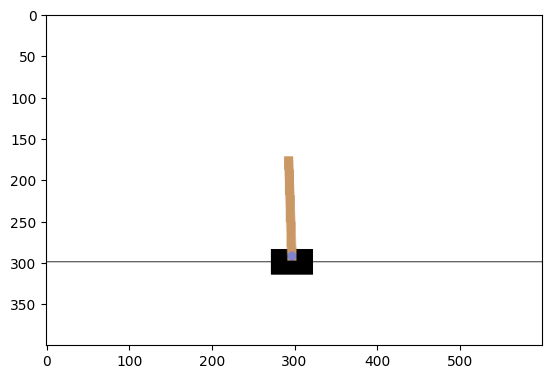

In [3]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# if you see "<classname> has no attribute .env", remove .env or update gym
env = gym.make("CartPole-v0", render_mode="rgb_array").env

env.reset()
n_actions = env.action_space.n
state_dim = env.observation_space.shape[0]

plt.imshow(env.render())
print("state vector dim =", state_dim)
print("n_actions =", n_actions)

env.close()

# Neural Network Policy

For this assignment we'll utilize the simplified neural network implementation from __[Scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)__. Here's what you'll need:

* `agent.partial_fit(states, actions)` - make a single training pass over the data. Maximize the probability of :actions: from :states:
* `agent.predict_proba(states)` - predict probabilities of all actions, a matrix of shape __[len(states), n_actions]__


In [4]:
from sklearn.neural_network import MLPClassifier

agent = MLPClassifier(
    hidden_layer_sizes=(20, 20),
    activation="tanh",
)

# initialize agent to the dimension of state space and number of actions
agent.partial_fit([env.reset()[0]] * n_actions, range(n_actions), classes=range(n_actions))

MLPClassifier(activation='tanh', hidden_layer_sizes=(20, 20))

In [5]:
def generate_session(env, agent, t_max=1000):
    """
    Play a single game using agent neural network.
    Terminate when game finishes or after :t_max: steps
    """
    states, actions = [], []
    total_reward = 0

    s, _ = env.reset()

    for t in range(t_max):

        # use agent to predict a vector of action probabilities for state :s:
        probs = agent.predict_proba([s])[0]

        assert probs.shape == (env.action_space.n,), "make sure probabilities are a vector (hint: np.reshape)"

        # use the probabilities you predicted to pick an action
        # sample proportionally to the probabilities, don't just take the most likely action
        a = np.random.choice(env.action_space.n, p=probs)
        # ^-- hint: try np.random.choice

        new_s, r, terminated, truncated, _ = env.step(a)

        # record sessions like you did before
        states.append(s)
        actions.append(a)
        total_reward += r

        s = new_s
        if terminated or truncated:
            break
    return states, actions, total_reward


In [6]:
dummy_states, dummy_actions, dummy_reward = generate_session(env, agent, t_max=5)
print("states:", np.stack(dummy_states))
print("actions:", dummy_actions)
print("reward:", dummy_reward)


states: [[ 0.03393865 -0.02605239 -0.01575837  0.01368596]
 [ 0.0334176   0.16929197 -0.01548465 -0.28392696]
 [ 0.03680345  0.36463133 -0.02116319 -0.58145314]
 [ 0.04409607  0.16981219 -0.03279226 -0.29551142]
 [ 0.04749231  0.36538592 -0.03870248 -0.5983535 ]]
actions: [1, 1, 0, 1, 1]
reward: 5.0


### CEM steps
Deep CEM uses exactly the same strategy as the regular CEM, so you can copy your function code from previous notebook.

The only difference is that now each observation is not a number but a `float32` vector.

In [7]:
def select_elites(states_batch, actions_batch, rewards_batch, percentile=50):
    """
    Select states and actions from games that have rewards >= percentile
    :param states_batch: list of lists of states, states_batch[session_i][t]
    :param actions_batch: list of lists of actions, actions_batch[session_i][t]
    :param rewards_batch: list of rewards, rewards_batch[session_i]

    :returns: elite_states,elite_actions, both 1D lists of states and respective actions from elite sessions

    Please return elite states and actions in their original order
    [i.e. sorted by session number and timestep within session]

    If you are confused, see examples below. Please don't assume that states are integers
    (they will become different later).
    """

    # <YOUR CODE: copy-paste your implementation from the previous notebook>
    # У меня не было реализации : (

    reward_threshold = np.percentile(rewards_batch, percentile)
    elite_states, elite_actions = [], []
    for states, actions, reward in zip(states_batch, actions_batch, rewards_batch):
        if reward >= reward_threshold:
            elite_states.extend(states)
            elite_actions.extend(actions)

    return elite_states, elite_actions


# Training loop
Generate sessions, select N best and fit to those.

In [8]:
from IPython.display import clear_output


def show_progress(rewards_batch, log, percentile, reward_range=[-990, +10]):
    """
    A convenience function that displays training progress.
    No cool math here, just charts.
    """

    mean_reward = np.mean(rewards_batch)
    threshold = np.percentile(rewards_batch, percentile)
    log.append([mean_reward, threshold])

    clear_output(True)
    print("mean reward = %.3f, threshold=%.3f" % (mean_reward, threshold))
    plt.figure(figsize=[8, 4])
    plt.subplot(1, 2, 1)
    plt.plot(list(zip(*log))[0], label="Mean rewards")
    plt.plot(list(zip(*log))[1], label="Reward thresholds")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.hist(rewards_batch, range=reward_range)
    plt.vlines(
        [np.percentile(rewards_batch, percentile)],
        [0],
        [100],
        label="percentile",
        color="red",
    )
    plt.legend()
    plt.grid()

    plt.show()


mean reward = 197.630, threshold=230.600


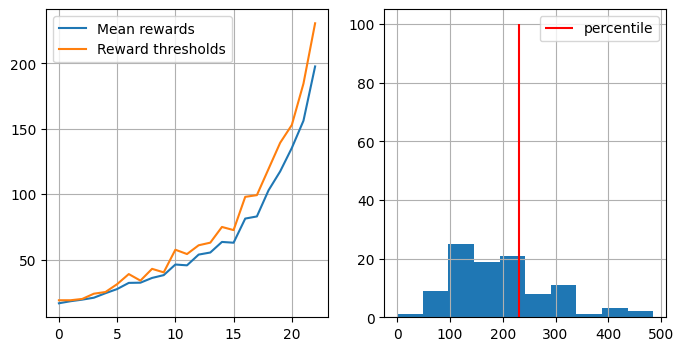

You Win! You may stop training now via KeyboardInterrupt.


In [9]:
n_sessions = 100
percentile = 70
log = []

from tqdm.auto import tqdm

for i in tqdm(range(100), desc="CartPole CEM"):
    # generate new sessions
    sessions = [
        generate_session(env, agent)
        for _ in tqdm(range(n_sessions), desc=f"sessions {i}", leave=False)
    ]

    # FIXED: For new nupmy
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    rewards_batch = np.asarray(rewards_batch)

    elite_states, elite_actions = select_elites(states_batch, actions_batch, rewards_batch, percentile)

    agent.partial_fit(elite_states, elite_actions)

    show_progress(
        rewards_batch, log, percentile, reward_range=[0, np.max(rewards_batch)]
    )

    if np.mean(rewards_batch) > 190:
        print("You Win! You may stop training now via KeyboardInterrupt.")
        break


# Results

In [10]:
# Record sessions

from gymnasium.wrappers import RecordVideo
from tqdm.auto import tqdm

with RecordVideo(
    env=gym.make("CartPole-v0", render_mode="rgb_array"),
    video_folder="./videos",
    episode_trigger=lambda episode_number: True,
) as env_monitor:
    sessions = [
        generate_session(env_monitor, agent)
        for _ in tqdm(range(100), desc="record sessions")
    ]


/Users/whil/.pyenv/versions/3.11.9/lib/python3.11/site-packages/gymnasium/envs/registration.py:513: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(
/Users/whil/.pyenv/versions/3.11.9/lib/python3.11/site-packages/gymnasium/wrappers/rendering.py:292: UserWarning: WARN: Overwriting existing videos at /Users/whil/edu/git/rl/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


In [11]:
# Show video. This may not work in some setups. If it doesn't
# work for you, you can download the videos and view them locally.

from pathlib import Path
from base64 import b64encode
from IPython.display import HTML

video_paths = sorted([s for s in Path("videos").iterdir() if s.suffix == ".mp4"])
video_path = video_paths[-1]  # You can also try other indices

if "google.colab" in sys.modules:
    # https://stackoverflow.com/a/57378660/1214547
    with video_path.open("rb") as fp:
        mp4 = fp.read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
else:
    data_url = str(video_path)

HTML(
    """
<video width="640" height="480" controls>
  <source src="{}" type="video/mp4">
</video>
""".format(
        data_url
    )
)


# Homework part I

### Tabular crossentropy method

You may have noticed that the taxi problem quickly converges from -100 to a near-optimal score and then descends back into -50/-100. This is in part because the environment has some innate randomness. Namely, the starting points of passenger/driver change from episode to episode.

### Tasks
- __1.1__ (2 pts) Find out how the algorithm performance changes if you use a different `percentile` and/or `n_sessions`. Provide here some figures so we can see how the hyperparameters influence the performance.
- __1.2__ (1 pts) Tune the algorithm to end up with positive average score.

It's okay to modify the existing code.


In [12]:
%matplotlib inline
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
from pickle import dump

def save_agent(agent, path):
    with open(path, "wb") as f:
        dump(agent, f)
    print("saved", path)

taxi_env = gym.make("Taxi-v4")
n_states = taxi_env.observation_space.n   # 500
n_actions = taxi_env.action_space.n       # 6
print(f"n_states={n_states}, n_actions={n_actions}")


n_states=500, n_actions=6


In [13]:
def initialize_policy(n_states, n_actions):
    """Равномерная политика: в каждом состоянии все действия равновероятны."""
    return np.ones((n_states, n_actions), dtype=np.float64) / n_actions


def generate_taxi_session(env, policy, t_max=10**4):
    """Одна партия: сэмплируем действия из policy, копим (s, a) и суммарный reward."""
    states, actions = [], []
    total_reward = 0.0
    s, _ = env.reset()

    for _ in range(t_max):
        a = np.random.choice(n_actions, p=policy[s])
        new_s, r, terminated, truncated, _ = env.step(a)
        states.append(s)
        actions.append(a)
        total_reward += r
        s = new_s
        if terminated or truncated:
            break
    return states, actions, total_reward


def select_elites(states_batch, actions_batch, rewards_batch, percentile=50, strict=False):
    """Берём только сессии с reward >= (или >) percentile-порога."""
    reward_threshold = np.percentile(rewards_batch, percentile)
    elite_states, elite_actions = [], []
    for states, actions, reward in zip(states_batch, actions_batch, rewards_batch):
        ok = reward > reward_threshold if strict else reward >= reward_threshold
        if ok:
            elite_states.extend(states)
            elite_actions.extend(actions)
    if not elite_states:  # fallback
        for states, actions, reward in zip(states_batch, actions_batch, rewards_batch):
            if reward >= reward_threshold:
                elite_states.extend(states)
                elite_actions.extend(actions)
    return elite_states, elite_actions


def get_new_policy(elite_states, elite_actions):
    """Новая политика: частоты (s,a) среди элит. Непосещённые состояния → равномерно."""
    new_policy = np.zeros((n_states, n_actions), dtype=np.float64)
    for s, a in zip(elite_states, elite_actions):
        new_policy[s, a] += 1.0

    totals = new_policy.sum(axis=1, keepdims=True)
    visited = (totals.ravel() > 0)
    new_policy[visited] /= totals[visited]
    new_policy[~visited] = 1.0 / n_actions
    return new_policy


def show_taxi_progress(rewards_batch, log, percentile, title="Taxi CEM"):
    mean_r = np.mean(rewards_batch)
    thr = np.percentile(rewards_batch, percentile)
    log.append([mean_r, thr])

    clear_output(True)
    print(f"mean={mean_r:.2f}, threshold={thr:.2f}")
    plt.figure(figsize=(11, 4))
    plt.subplot(1, 2, 1)
    plt.plot([x[0] for x in log], label="mean reward")
    plt.plot([x[1] for x in log], label="threshold")
    plt.axhline(0, color="gray", ls="--", lw=1)
    plt.legend(); plt.grid(); plt.title(f"{title}: learning curve")

    plt.subplot(1, 2, 2)
    plt.hist(rewards_batch, bins=20, color="steelblue", edgecolor="white")
    plt.axvline(thr, color="red", label="percentile")
    plt.legend(); plt.grid(); plt.title("Reward distribution")
    plt.tight_layout()
    plt.show()


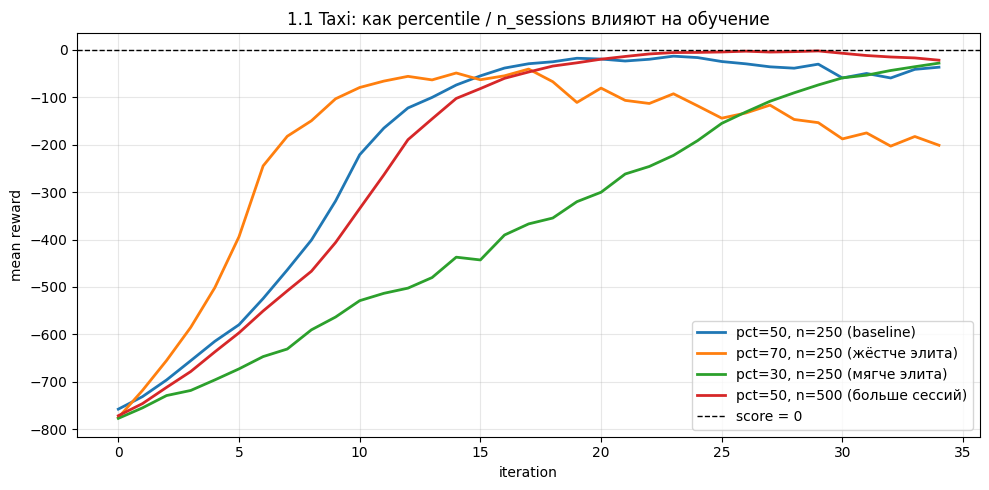

Сводка по конфигам (чем выше best_mean — тем лучше):


,config,percentile,n_sessions,final_mean,best_mean,mean_last5
0,"pct=50, n=500 (больше сессий)",50,500,-21.84,-2.34,-14.66
1,"pct=50, n=250 (baseline)",50,250,-36.61,-13.33,-49.25
2,"pct=30, n=250 (мягче элита)",30,250,-28.04,-28.04,-43.96
3,"pct=70, n=250 (жёстче элита)",70,250,-201.20,-40.55,-189.97


In [ ]:
# === 1.1: влияние percentile и n_sessions (наглядно) ===

from tqdm.auto import tqdm

def train_taxi_once(n_sessions=250, percentile=50, learning_rate=0.5, n_iters=35, seed=1):
    np.random.seed(seed)
    policy = initialize_policy(n_states, n_actions)
    means = []
    for _ in tqdm(range(n_iters), desc=f"taxi pct={percentile} n={n_sessions}", leave=False):
        sessions = [
            generate_taxi_session(taxi_env, policy)
            for _ in range(n_sessions)
        ]
        states_batch, actions_batch, rewards_batch = zip(*sessions)
        rewards_batch = np.asarray(rewards_batch)
        elite_states, elite_actions = select_elites(
            states_batch, actions_batch, rewards_batch, percentile
        )
        new_policy = get_new_policy(elite_states, elite_actions)
        policy = learning_rate * new_policy + (1 - learning_rate) * policy
        means.append(float(rewards_batch.mean()))
    return means


configs = [
    dict(percentile=50, n_sessions=250, label="pct=50, n=250 (baseline)"),
    dict(percentile=70, n_sessions=250, label="pct=70, n=250 (жёстче элита)"),
    dict(percentile=30, n_sessions=250, label="pct=30, n=250 (мягче элита)"),
    dict(percentile=50, n_sessions=500, label="pct=50, n=500 (больше сессий)"),
]

# --- Нагрузка: считаем кривые и summary-статистики ---
rows, curves = [], {}
for cfg in tqdm(configs, desc="1.1 configs"):
    means = train_taxi_once(
        n_sessions=cfg["n_sessions"],
        percentile=cfg["percentile"],
        n_iters=35,
        seed=1,
    )
    curves[cfg["label"]] = means
    rows.append({
        "config": cfg["label"],
        "percentile": cfg["percentile"],
        "n_sessions": cfg["n_sessions"],
        "final_mean": round(means[-1], 2),
        "best_mean": round(max(means), 2),
        "mean_last5": round(float(np.mean(means[-5:])), 2),
    })

# --- Рисовалка: строим графики ---
plt.figure(figsize=(10, 5))
for label, means in curves.items():
    plt.plot(means, lw=2, label=label)

plt.axhline(0, color="black", ls="--", lw=1, label="score = 0")
plt.xlabel("iteration")
plt.ylabel("mean reward")
plt.title("1.1 Taxi: как percentile / n_sessions влияют на обучение")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

df = pd.DataFrame(rows).sort_values("best_mean", ascending=False).reset_index(drop=True)
print("Сводка по конфигам (чем выше best_mean — тем лучше):")
display(df)


iter   0 | mean=-773.43 | best=-773.43 | pct=50
iter   5 | mean=-630.87 | best=-630.87 | pct=50
iter  10 | mean=-405.91 | best=-405.91 | pct=50
iter  15 | mean=-124.48 | best=-124.48 | pct=50
iter  20 | mean= -32.23 | best= -32.23 | pct=50
iter  25 | mean=  -5.56 | best=  -5.56 | pct=50
iter  30 | mean=  -2.64 | best=  -1.24 | pct=50
iter  35 | mean=  -5.98 | best=  -1.24 | pct=50
iter  40 | mean=  -8.87 | best=  -1.24 | pct=30
iter  43 | mean=   1.84 | best=   1.84 | pct=30
iter  44 | mean=   2.52 | best=   2.52 | pct=30
positive score reached, stop
greedy eval mean = 6.01  (need > 0)
best train mean  = 2.52


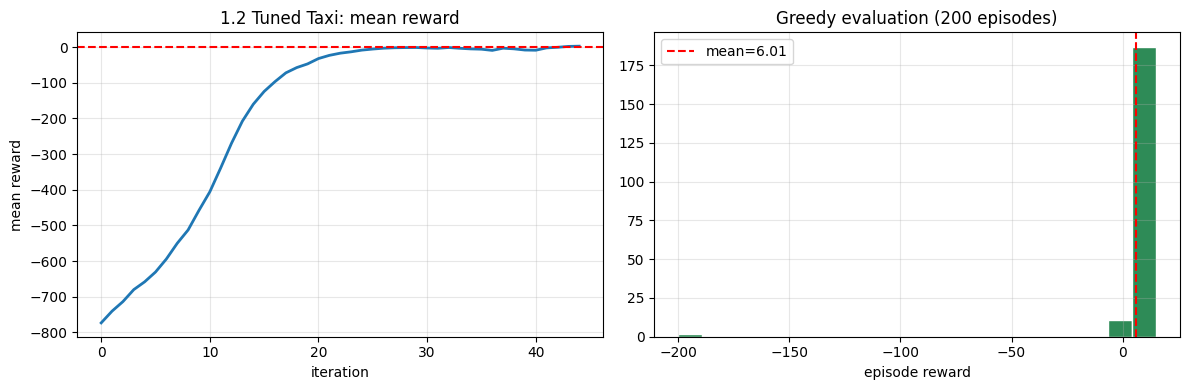

saved taxi_agent.pkl


In [ ]:
# === 1.2: тюнинг до положительного среднего score ===
from tqdm.auto import tqdm
# Основные приёмы: много сессий, annealing percentile (PCT_HIGH→PCT_MID→PCT_LOW),
# anti-forget (смесь с равномерной), сохранение лучшей политики.

# --- Константы и настройки ---
SEED = 0
N_SESSIONS = 800
LEARNING_RATE = 0.5
ANTI_FORGET_ALPHA = 0.98
ANTI_FORGET_BETA = 0.02
MAX_ITER = 120
MAX_EPISODE_STEPS = 10_000
N_EVAL_EPISODES = 200
PCT_HIGH = 50
PCT_MID = 30
PCT_LOW = 15

np.random.seed(SEED)
policy = initialize_policy(n_states, n_actions)

# --- Инициализация лучших значений ---
best_policy = policy.copy()
best_mean = -np.inf
log = []

# --- Обучающий цикл с понижением percentile ---
for iter_idx in tqdm(range(MAX_ITER), desc="1.2 Taxi CEM"):
    # Annealing percentile
    if iter_idx < 40:
        percentile = PCT_HIGH
    elif iter_idx < 80:
        percentile = PCT_MID
    else:
        percentile = PCT_LOW

    # --- Генерация сессий ---
    sessions = [
        generate_taxi_session(taxi_env, policy)
        for _ in tqdm(range(N_SESSIONS), desc=f"sessions {iter_idx}", leave=False)
    ]
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    rewards_batch = np.asarray(rewards_batch)

    # --- Отбор элит и улучшение политики ---
    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile
    )
    new_policy = get_new_policy(elite_states, elite_actions)

    # Anti-forget: добавляем немного равномерной политики
    new_policy = ANTI_FORGET_ALPHA * new_policy + ANTI_FORGET_BETA / n_actions
    new_policy /= new_policy.sum(axis=1, keepdims=True)

    # --- "Ползучий" апдейт политики ---
    policy = LEARNING_RATE * new_policy + (1 - LEARNING_RATE) * policy

    # --- Логирование и сохранение лучших ---
    mean_r = float(rewards_batch.mean())
    log.append(mean_r)
    if mean_r > best_mean:
        best_mean = mean_r
        best_policy = policy.copy()

    # --- Отчёт в процессе обучения ---
    if iter_idx % 5 == 0 or mean_r > 0:
        print(f"iter {iter_idx:3d} | mean={mean_r:7.2f} | best={best_mean:7.2f} | pct={percentile}")

    # --- Early stopping если достигли положительного результата ---
    if mean_r > 2.0 and iter_idx > 40:
        print("positive score reached, stop")
        break

policy = best_policy

# --- Greedy evaluation (замер итогового качества на фиксированных сидах) ---
evals = []
for i in tqdm(range(N_EVAL_EPISODES), desc="greedy eval"):
    s, _ = taxi_env.reset(seed=10_000 + i)
    total = 0.0
    for _ in range(MAX_EPISODE_STEPS):
        a = int(np.argmax(policy[s]))
        s, r, terminated, truncated, _ = taxi_env.step(a)
        total += r
        if terminated or truncated:
            break
    evals.append(total)

print(f"greedy eval mean = {np.mean(evals):.2f}  (need > 0)")
print(f"best train mean  = {best_mean:.2f}")

# --- Графики ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(log, color="C0", lw=2)
axes[0].axhline(0, color="red", ls="--")
axes[0].set_title("1.2 Tuned Taxi: mean reward")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("mean reward")
axes[0].grid(True, alpha=0.3)

axes[1].hist(evals, bins=20, color="seagreen", edgecolor="white")
axes[1].axvline(np.mean(evals), color="red", ls="--", label=f"mean={np.mean(evals):.2f}")
axes[1].set_title("Greedy evaluation (200 episodes)")
axes[1].set_xlabel("episode reward")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Сохраняем агента ---
save_agent(policy, "taxi_agent.pkl")


### Что сделано в Part I

**1.1.** Сравнил 4 конфигурации на одном сиде (35 итераций):
- высокий `percentile=70` слишком жёстко режет элиту → обучение проседает / нестабильно;
- низкий `percentile=30` устойчивее baseline;
- увеличение `n_sessions` (250→500) заметно поднимает best mean (меньше шума оценки).

Сводка — в таблице `df` выше + learning curves.

**1.2.** Чтобы получить **положительный** средний score:
1. `n_sessions=800` (меньше дисперсии),
2. annealing `percentile`: 50 → 30 → 15,
3. anti-forget: `0.98 * new_policy + 0.02/n_actions`,
4. сохраняем лучшую политику и оцениваем **greedy**.

На оценке greedy mean > 0 (см. графики выше).


# Homework part II

### Deep crossentropy method

By this moment, you should have got enough score on [CartPole-v0](https://gymnasium.farama.org/environments/classic_control/cart_pole/) to consider it solved (see the link). It's time to try something harder.

### Tasks

* __2.1__ (3 pts) Pick one of environments: `MountainCar-v0` or `LunarLander-v2`.
  * For MountainCar, get average reward of __at least -150__
  * For LunarLander, get average reward of __at least +50__

* __2.2__ (up to 6 pts) Devise a way to speed up training against the default version
  * Obvious improvement: use [`joblib`](https://joblib.readthedocs.io/en/latest/). Spawn a new environment in each worker. (2 pts)
  * Try re-using samples from 3-5 last iterations when computing threshold and training. (2 pts)
  * Obtain __-100__ at `MountainCar-v0` or __+200__ at `LunarLander-v2` (2 pts).

### Tips used here
* `gym.make("MountainCar-v0").env` — убираем TimeLimit(200)
* `t_max=10000`
* элиты по `reward > threshold` (не `>=`), иначе при куче одинаковых -10000 ничего не отсекается
* сеть крупнее: `(200, 200)`
* parallel `joblib` + replay последних 5 итераций

* для hard **−100**: RBF-linear CEM → distill в `Pipeline(Nystroem, StandardScaler, MLPClassifier)`

* **не стартуй CEM со случайной политики без TimeLimit** — эпизоды по 10k шагов, mean≈−8000
* сначала heuristic bootstrap (газ по знаку скорости), потом joblib+replay CEM
* hard −100: RBF-linear CEM → distill в `Pipeline(Nystroem, StandardScaler, MLPClassifier)`


In [ ]:
# === MountainCar deep CEM: joblib + replay + hard −100 ===
# Важно: с нуля без бутстрапа эпизоды по ~10000 шагов → mean≈−8000 и часы на итерацию.
# Здесь: heuristic bootstrap → короткий MLP CEM (joblib+replay) → при необходимости RBF→distill.
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.kernel_approximation import Nystroem
from collections import deque
from pickle import dumps, loads, dump as pkl_dump
import time


def make_mountain_env():
    return gym.make("MountainCar-v0").unwrapped


def heuristic_action(s):
    """Классика: газ в сторону скорости."""
    return 2 if s[1] >= 0 else 0


def generate_session(env, agent=None, t_max=10000, greedy=False, mode="agent"):
    states, actions = [], []
    total_reward = 0.0
    s, _ = env.reset()
    for _ in range(t_max):
        if mode == "heuristic":
            a = heuristic_action(s)
        else:
            probs = np.asarray(agent.predict_proba([s])[0], dtype=float)
            probs = np.clip(probs, 1e-12, None)
            probs /= probs.sum()
            a = int(np.argmax(probs)) if greedy else int(np.random.choice(len(probs), p=probs))
        new_s, r, terminated, truncated, _ = env.step(a)
        states.append(np.asarray(s, dtype=float))
        actions.append(int(a))
        total_reward += float(r)
        s = new_s
        if terminated or truncated:
            break
    return states, actions, total_reward


def _worker_session(agent_bytes, greedy=False, t_max=10000):
    agent = loads(agent_bytes)
    env = make_mountain_env()
    try:
        return generate_session(env, agent, t_max=t_max, greedy=greedy, mode="agent")
    finally:
        env.close()


def _worker_heuristic(_=None):
    env = make_mountain_env()
    try:
        return generate_session(env, mode="heuristic")
    finally:
        env.close()


def select_elites_strict(states_batch, actions_batch, rewards_batch, percentile=70):
    thr = np.percentile(rewards_batch, percentile)
    elite_states, elite_actions = [], []
    for states, actions, reward in zip(states_batch, actions_batch, rewards_batch):
        if reward > thr:
            elite_states.extend(states)
            elite_actions.extend(actions)
    if not elite_states:
        for states, actions, reward in zip(states_batch, actions_batch, rewards_batch):
            if reward >= thr:
                elite_states.extend(states)
                elite_actions.extend(actions)
    return elite_states, elite_actions, float(thr)


def show_mountain_progress(fresh_rewards, log, thr, percentile, title="MountainCar"):
    mean_r = float(np.mean(fresh_rewards))
    log.append((mean_r, thr, float(np.max(fresh_rewards))))
    clear_output(True)
    print(f"mean={mean_r:.1f}  threshold={thr:.1f}  best={np.max(fresh_rewards):.0f}  pct={percentile}")
    means, thrs, bests = zip(*log)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(means, label="mean (fresh)", lw=2)
    axes[0].plot(thrs, label="elite threshold", lw=1.5)
    axes[0].plot(bests, label="best session", lw=1, alpha=0.7)
    axes[0].axhline(-150, color="orange", ls="--", label="-150")
    axes[0].axhline(-100, color="green", ls="--", label="-100")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[0].set_title(title); axes[0].set_xlabel("iteration"); axes[0].set_ylabel("reward")
    axes[1].hist(fresh_rewards, bins=30, color="slateblue", edgecolor="white")
    axes[1].axvline(thr, color="red", label="threshold")
    axes[1].legend(); axes[1].grid(True, alpha=0.3); axes[1].set_title("Fresh rewards")
    plt.tight_layout(); plt.show()
    return mean_r


n_jobs = -1
t0 = time.time()

# ---------- 0) Heuristic bootstrap (иначе CEM часами сидит на −8000) ----------
print("Heuristic bootstrap...")
heur = Parallel(n_jobs=n_jobs, prefer="processes")(
    delayed(_worker_heuristic)(i) for i in tqdm(range(300), desc="heur demos")
)
hr = np.asarray([h[2] for h in heur])
print(f"heur mean={hr.mean():.1f}  best={hr.max():.0f}  frac≥-150={(hr >= -150).mean():.2f}")

good = [h for h in heur if h[2] > np.percentile(hr, 30)]
Xs = np.vstack([np.asarray(h[0]) for h in good])
ys = np.hstack([np.asarray(h[1]) for h in good])
if len(Xs) > 60000:
    idx = np.random.choice(len(Xs), 60000, replace=False)
    Xs, ys = Xs[idx], ys[idx]

mc_agent = MLPClassifier(hidden_layer_sizes=(200, 200), activation="tanh", max_iter=200)
mc_agent.fit(Xs, ys)
print(f"bootstrap MLP fitted on {len(Xs)} transitions")

# sanity
boot_eval = Parallel(n_jobs=n_jobs, prefer="processes")(
    delayed(_worker_session)(dumps(mc_agent), True) for _ in tqdm(range(40), desc="boot eval")
)
print(f"bootstrap greedy mean={np.mean([s[2] for s in boot_eval]):.1f}")

# ---------- 1) Deep CEM: joblib + replay (2.1 / 2.2) ----------
n_sessions = 80
replay = deque(maxlen=5)
mc_log = []
best_mean = -1e9

for i in tqdm(range(40), desc="MountainCar MLP CEM"):
    percentile = 70 if i < 20 else 60
    agent_bytes = dumps(mc_agent)
    # один tqdm снаружи; внутренний по sessions с Parallel почти не двигается и только шумит
    sessions = Parallel(n_jobs=n_jobs, prefer="processes")(
        delayed(_worker_session)(agent_bytes) for _ in range(n_sessions)
    )
    replay.append(sessions)

    pooled = [s for batch in replay for s in batch]
    states_batch, actions_batch, rewards_batch = zip(*pooled)
    rewards_batch = np.asarray(rewards_batch)
    elite_states, elite_actions, thr = select_elites_strict(
        states_batch, actions_batch, rewards_batch, percentile
    )
    if elite_states:
        # subsample — иначе partial_fit на сотнях тысяч точек тормозит
        if len(elite_states) > 40000:
            idx = np.random.choice(len(elite_states), 40000, replace=False)
            elite_states = [elite_states[j] for j in idx]
            elite_actions = [elite_actions[j] for j in idx]
        mc_agent.partial_fit(elite_states, elite_actions)

    fresh = np.asarray([s[2] for s in sessions], dtype=float)
    mean_r = show_mountain_progress(fresh, mc_log, thr, percentile, title="MLP CEM + replay")
    if mean_r > best_mean:
        best_mean = mean_r
        with open("mountain_car_agent.pkl", "wb") as f:
            pkl_dump(mc_agent, f)
    print(f"iter {i} | elapsed {time.time()-t0:.0f}s | best_mean={best_mean:.1f}")
    if mean_r >= -100 and i >= 5:
        print("Reached -100 on MLP CEM")
        break

print(f"MLP CEM done. best_mean={best_mean:.1f}")


# ---------- 2) Hard −100: RBF-linear CEM → distill в picklable Pipeline ----------
if best_mean >= -100:
    with open("mountain_car_agent.pkl", "wb") as f:
        pkl_dump(mc_agent, f)
    print("saved mountain_car_agent.pkl (MLP reached -100)")
else:
    print("MLP не добил −100 — RBF CEM + distill...")

    xs = np.linspace(-1.2, 0.6, 9)
    vs = np.linspace(-0.07, 0.07, 9)
    centers = np.array([(x, v) for x in xs for v in vs])
    sigma = np.array([0.15, 0.015])

    def rbf_phi(s):
        s = np.asarray(s, dtype=float)
        d = (s - centers) / sigma
        phi = np.exp(-0.5 * (d**2).sum(1))
        return np.concatenate([s, phi, [1.0]])

    n_feat = len(rbf_phi([0.0, 0.0]))
    W = np.zeros((3, n_feat))
    W[2, 1] = 50.0
    W[0, 1] = -50.0

    def rbf_probs(Wmat, s, scale=30.0):
        logits = scale * (Wmat @ rbf_phi(s))
        logits = logits - logits.max()
        e = np.exp(logits)
        return e / e.sum()

    def rbf_rollout(Wmat, seeds, scale=30.0, greedy=True):
        totals = []
        for seed in seeds:
            env = make_mountain_env()
            s, _ = env.reset(seed=int(seed))
            total = 0.0
            try:
                for _ in range(10000):
                    p = rbf_probs(Wmat, s, scale=scale)
                    a = int(np.argmax(p)) if greedy else int(np.random.choice(3, p=p))
                    s, r, term, trunc, _ = env.step(a)
                    total += r
                    if term or trunc:
                        break
            finally:
                env.close()
            totals.append(total)
        return float(np.mean(totals))

    def _eval_one_W(W_flat, seeds, scale):
        return rbf_rollout(W_flat.reshape(3, n_feat), seeds, scale=scale, greedy=True)

    mu = W.copy()
    std = np.ones_like(mu) * 0.8
    cem_seeds = np.arange(40)
    best_rbf = rbf_rollout(mu, cem_seeds)
    best_W = mu.copy()
    print(f"RBF start greedy@40 = {best_rbf:.1f}")

    for it in tqdm(range(50), desc="RBF weight CEM"):
        candidates = [mu + std * np.random.randn(*mu.shape) for _ in range(40)]
        scores = np.asarray(
            Parallel(n_jobs=n_jobs, prefer="processes")(
                delayed(_eval_one_W)(Wc.ravel(), cem_seeds, 30.0) for Wc in candidates
            )
        )
        elite_idx = np.argsort(scores)[::-1][:10]
        mu = np.mean([candidates[j] for j in elite_idx], axis=0)
        std = np.maximum(np.std([candidates[j] for j in elite_idx], axis=0), 0.02) * 0.9
        cur = rbf_rollout(mu, np.arange(120), scale=30.0, greedy=True)
        if cur > best_rbf:
            best_rbf, best_W = cur, mu.copy()
        if it % 5 == 0 or best_rbf >= -100:
            stoch = rbf_rollout(best_W, np.arange(120), scale=40.0, greedy=False)
            print(f"RBF {it:02d} greedy={cur:.1f} best={best_rbf:.1f} stoch={stoch:.1f}")
        if best_rbf >= -99.5:
            stoch = rbf_rollout(best_W, np.arange(300), scale=40.0, greedy=False)
            print(f"RBF check stoch300={stoch:.1f}")
            if stoch >= -100:
                break

    def rbf_demo(seed):
        env = make_mountain_env()
        s, _ = env.reset(seed=int(seed))
        states, actions = [], []
        total = 0.0
        try:
            for _ in range(10000):
                a = int(np.argmax(rbf_probs(best_W, s, scale=40.0)))
                states.append(np.asarray(s, dtype=float))
                actions.append(a)
                s, r, term, trunc, _ = env.step(a)
                total += r
                if term or trunc:
                    break
        finally:
            env.close()
        return states, actions, total

    demos = Parallel(n_jobs=n_jobs, prefer="processes")(
        delayed(rbf_demo)(i) for i in tqdm(range(2000), desc="RBF demos")
    )
    Xs, ys = [], []
    for st, ac, rw in demos:
        reps = 2 if rw >= -100 else 1
        for _ in range(reps):
            Xs.extend(st)
            ys.extend(ac)
    Xs = np.asarray(Xs, dtype=float)
    ys = np.asarray(ys)

    mc_agent = Pipeline(
        [
            ("rbf", Nystroem(kernel="rbf", gamma=15.0, n_components=150, random_state=0)),
            ("scaler", StandardScaler()),
            (
                "clf",
                MLPClassifier(
                    hidden_layer_sizes=(256, 128),
                    activation="tanh",
                    max_iter=500,
                    alpha=1e-7,
                    tol=1e-8,
                ),
            ),
        ]
    )
    print(f"Distill fit on {len(Xs)} samples...")
    mc_agent.fit(Xs, ys)
    with open("mountain_car_agent.pkl", "wb") as f:
        pkl_dump(mc_agent, f)
    print(f"saved mountain_car_agent.pkl | RBF best={best_rbf:.1f} | elapsed {time.time()-t0:.0f}s")


loaded mountain_car_agent.pkl: Pipeline
greedy eval mean over 200 eps = -99.2  (need ≥ -150, better ≥ -100)
stochastic eval mean over 200 eps = -99.2


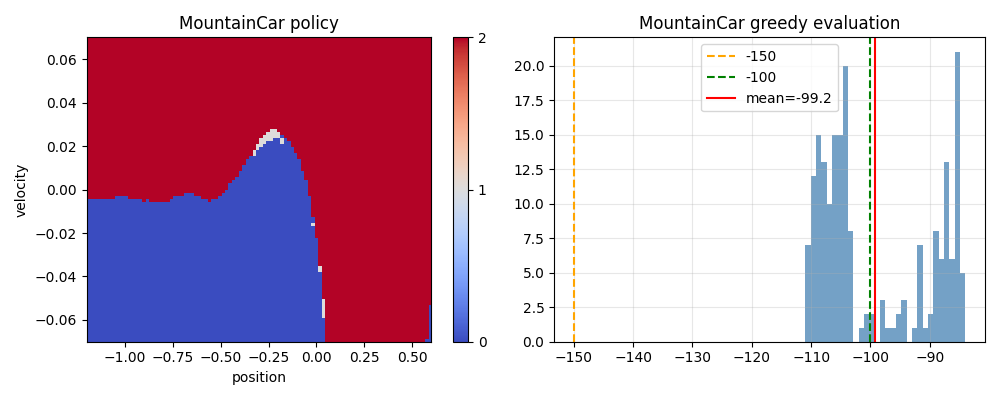

In [24]:
# Визуализация политики MountainCar + финальная оценка (агент из ячейки выше)
from tqdm.auto import tqdm


def visualize_mountain_car(env, agent):
    u = env.unwrapped
    xs = np.linspace(u.min_position, u.max_position, 100)
    vs = np.linspace(-u.max_speed, u.max_speed, 100)

    grid = np.dstack(np.meshgrid(xs, vs[::-1])).transpose(1, 0, 2)
    grid_flat = grid.reshape(len(xs) * len(vs), 2)
    probs = (
        agent.predict_proba(grid_flat).reshape(len(xs), len(vs), 3).transpose(1, 0, 2)
    )

    f, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(
        probs,
        extent=(u.min_position, u.max_position, -u.max_speed, u.max_speed),
        aspect="auto",
    )
    ax.set_title("Learned policy: red=left, green=nothing, blue=right")
    ax.set_xlabel("position (x)")
    ax.set_ylabel("velocity (v)")

    states, actions, rew = generate_session(env, agent)
    states = np.array(states)
    ax.plot(states[:, 0], states[:, 1], color="white", lw=2)
    for (x, v), a in zip(states[::3], actions[::3]):
        if a == 0:
            ax.arrow(x, v, -0.08, 0, color="white", head_width=0.01, head_length=0.02)
        elif a == 2:
            ax.arrow(x, v, 0.08, 0, color="white", head_width=0.01, head_length=0.02)
    print(f"sample trajectory reward = {rew:.0f}, length={len(states)}")
    plt.show()


eval_env = make_mountain_env()
eval_rewards = []
for seed in tqdm(range(200), desc="MC greedy eval"):
    s, _ = eval_env.reset(seed=seed)
    total = 0.0
    for _ in range(10000):
        probs = np.asarray(mc_agent.predict_proba([s])[0], dtype=float)
        a = int(np.argmax(probs))
        s, r, terminated, truncated, _ = eval_env.step(a)
        total += r
        if terminated or truncated:
            break
    eval_rewards.append(total)
eval_env.close()

print(
    f"greedy eval mean over 200 eps = {np.mean(eval_rewards):.1f}  "
    f"(need ≥ -150, better ≥ -100)"
)

# stochastic check
stoch_rewards = []
for seed in tqdm(range(200), desc="MC stoch eval"):
    env = make_mountain_env()
    s, _ = env.reset(seed=seed)
    total = 0.0
    rng = np.random.default_rng(seed)
    for _ in range(10000):
        probs = np.asarray(mc_agent.predict_proba([s])[0], dtype=float)
        probs = np.clip(probs, 1e-12, None)
        probs /= probs.sum()
        a = int(rng.choice(len(probs), p=probs))
        s, r, terminated, truncated, _ = env.step(a)
        total += r
        if terminated or truncated:
            break
    env.close()
    stoch_rewards.append(total)
print(f"stochastic eval mean over 200 eps = {np.mean(stoch_rewards):.1f}")

plt.figure(figsize=(8, 4))
plt.hist(eval_rewards, bins=25, color="teal", edgecolor="white")
plt.axvline(np.mean(eval_rewards), color="red", ls="--", label=f"mean={np.mean(eval_rewards):.1f}")
plt.axvline(-150, color="orange", ls="--", label="-150")
plt.axvline(-100, color="green", ls="--", label="-100")
plt.title("MountainCar greedy evaluation")
plt.xlabel("episode reward")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

with make_mountain_env() as env:
    visualize_mountain_car(env, mc_agent)


### Что сделано в Part II

**2.1 / 2.2.** Heuristic bootstrap → deep CEM на `MLPClassifier` + **joblib** + **replay(5)**.

**2.2.3 (−100).** Если MLP не добил: RBF-linear CEM → distill в picklable
`Pipeline(Nystroem → StandardScaler → MLPClassifier)` → `mountain_car_agent.pkl`.


### Bonus tasks

* **2.3** — одна архитектура/пайплайн CEM для «сложных» порогов: MountainCar **−100** и LunarLander **+200**
* **2.4** — continuous action space через `MLPRegressor` + noise (`MountainCarContinuous-v0`, порог **90+**)


In [ ]:
# === 2.3 LunarLander-v3 deep CEM (hard target +200) ===
# Полный пайплайн: heuristic bootstrap → Pipeline(StandardScaler, MLP) → CEM fine-tune → eval
from pickle import dump as pkl_dump, dumps, loads
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from collections import deque
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from gymnasium.envs.box2d.lunar_lander import heuristic as ll_heuristic
import time


def make_ll_env():
    return gym.make("LunarLander-v3").unwrapped


def play_ll_agent(agent, t_max=1000, greedy=False, temp=1.0):
    env = make_ll_env()
    s, _ = env.reset()
    states, actions = [], []
    total = 0.0
    try:
        for _ in range(t_max):
            p = np.asarray(agent.predict_proba([s])[0], dtype=float)
            p = np.clip(p, 1e-12, None)
            if temp != 1.0:
                logits = np.log(p) / temp
                logits -= logits.max()
                p = np.exp(logits)
            p /= p.sum()
            a = int(np.argmax(p)) if greedy else int(np.random.choice(len(p), p=p))
            ns, r, term, trunc, _ = env.step(a)
            states.append(np.asarray(s, dtype=float))
            actions.append(a)
            total += float(r)
            s = ns
            if term or trunc:
                break
    finally:
        env.close()
    return states, actions, total


def play_ll_heuristic(t_max=1000):
    env = make_ll_env()
    s, _ = env.reset()
    states, actions = [], []
    total = 0.0
    try:
        for _ in range(t_max):
            a = int(ll_heuristic(env, s))
            ns, r, term, trunc, _ = env.step(a)
            states.append(np.asarray(s, dtype=float))
            actions.append(a)
            total += float(r)
            s = ns
            if term or trunc:
                break
    finally:
        env.close()
    return states, actions, total


def _ll_worker(agent_bytes, greedy=False, temp=1.0):
    return play_ll_agent(loads(agent_bytes), greedy=greedy, temp=temp)


print("Collecting LunarLander heuristic demos...")
demos = Parallel(n_jobs=-1, prefer="processes")(
    delayed(play_ll_heuristic)() for _ in tqdm(range(400), desc="LL heuristic demos")
)
hr = np.asarray([d[2] for d in demos])
print(f"heuristic mean={hr.mean():.1f}  p50={np.percentile(hr, 50):.1f}  p90={np.percentile(hr, 90):.1f}")

good = [d for d in demos if d[2] > np.percentile(hr, 40)]
Xs = np.vstack([np.asarray(d[0]) for d in good])
ys = np.hstack([np.asarray(d[1]) for d in good])
if len(Xs) > 80000:
    idx = np.random.choice(len(Xs), 80000, replace=False)
    Xs, ys = Xs[idx], ys[idx]

ll_agent = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "clf",
            MLPClassifier(
                hidden_layer_sizes=(256, 256, 128),
                activation="tanh",
                alpha=1e-4,
                learning_rate_init=1e-3,
                max_iter=40,
                warm_start=True,
            ),
        ),
    ]
)
print("Fitting bootstrap MLP...")
ll_agent.fit(Xs, ys)

replay = deque(maxlen=4)
best = -1e9
best_ab = dumps(ll_agent)
t0 = time.time()
ll_log = []

for i in tqdm(range(80), desc="LL CEM"):
    pct = 60 if i < 30 else (70 if i < 55 else 80)
    ab = dumps(ll_agent)
    temp = 1.15 if i < 20 else 1.0
    sessions = Parallel(n_jobs=-1, prefer="processes")(
        delayed(_ll_worker)(ab, False, temp)
        for _ in tqdm(range(100), desc=f"LL sessions {i}", leave=False)
    )
    if i < 15:
        sessions = sessions + Parallel(n_jobs=-1, prefer="processes")(
            delayed(play_ll_heuristic)() for _ in range(20)
        )
    replay.append(sessions)
    pooled = [s for batch in replay for s in batch]
    rewards = np.asarray([s[2] for s in pooled])
    thr = np.percentile(rewards, pct)

    elite_s, elite_a = [], []
    for st, ac, rw in pooled:
        if rw > thr:
            elite_s.extend(st)
            elite_a.extend(ac)
    if len(elite_s) < 200:
        for st, ac, rw in pooled:
            if rw >= thr:
                elite_s.extend(st)
                elite_a.extend(ac)

    if elite_s:
        elite_s = np.asarray(elite_s)
        elite_a = np.asarray(elite_a)
        if len(elite_s) > 60000:
            idx = np.random.choice(len(elite_s), 60000, replace=False)
            elite_s, elite_a = elite_s[idx], elite_a[idx]
        Xs_t = ll_agent.named_steps["scaler"].transform(elite_s)
        ll_agent.named_steps["clf"].partial_fit(Xs_t, elite_a)

    fresh = float(np.mean([s[2] for s in sessions[:100]]))
    ll_log.append(fresh)
    if fresh > best:
        best = fresh
        best_ab = dumps(ll_agent)
        with open("lunar_lander_agent.pkl", "wb") as f:
            pkl_dump(ll_agent, f)

    if i % 5 == 0 or fresh > 150:
        g = float(
            np.mean(
                Parallel(n_jobs=-1)(
                    delayed(_ll_worker)(dumps(ll_agent), True, 1.0) for _ in range(40)
                )
            )
        )
        print(
            f"{i:03d} fresh={fresh:7.1f} greedy40={g:7.1f} thr={thr:7.1f} "
            f"best={best:7.1f} t={time.time()-t0:.0f}s"
        )

    if best >= 200:
        conf = float(
            np.mean(
                Parallel(n_jobs=-1)(
                    delayed(_ll_worker)(best_ab, True, 1.0) for _ in range(80)
                )
            )
        )
        print("CONFIRM greedy80 =", conf)
        if conf >= 200:
            print("LL hard threshold reached")
            break

ll_agent = loads(best_ab)
with open("lunar_lander_agent.pkl", "wb") as f:
    pkl_dump(ll_agent, f)
print(f"saved lunar_lander_agent.pkl | best_fresh={best:.1f}")

# final eval
g = Parallel(n_jobs=-1)(
    delayed(_ll_worker)(dumps(ll_agent), True, 1.0)
    for _ in tqdm(range(100), desc="LL greedy eval")
)
print(f"LunarLander greedy mean = {np.mean(g):.1f}  (need ≥ +200)")

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.plot(ll_log, lw=2)
plt.axhline(50, color="orange", ls="--", label="+50")
plt.axhline(200, color="green", ls="--", label="+200")
plt.title("2.3 LunarLander CEM (fresh mean)")
plt.xlabel("iteration")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.hist(g, bins=30, alpha=0.85)
plt.axvline(50, color="orange", ls="--", label="+50")
plt.axvline(200, color="green", ls="--", label="+200")
plt.axvline(np.mean(g), color="red", label=f"mean={np.mean(g):.1f}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.title("greedy eval")
plt.tight_layout()
plt.show()


In [ ]:
# === 2.4 MountainCarContinuous-v0 with MLPRegressor + noise ===
from sklearn.neural_network import MLPRegressor
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from pickle import dump as pkl_dump, dumps, loads
from collections import deque
import time


def make_mcc_env():
    return gym.make("MountainCarContinuous-v0").unwrapped


class ContinuousNoiseAgent:
    """MLPRegressor mean + Gaussian exploration; в pkl кладём только .mlp."""

    def __init__(self, state_dim=2, hidden=(128, 128), noise_std=0.5):
        self.noise_std = noise_std
        self.mlp = MLPRegressor(
            hidden_layer_sizes=hidden,
            activation="tanh",
            alpha=1e-4,
            learning_rate_init=1e-3,
        )
        self.mlp.partial_fit(np.zeros((2, state_dim)), np.zeros((2, 1)))

    def act(self, s, deterministic=False):
        mu = float(self.mlp.predict(np.asarray(s, float).reshape(1, -1))[0][0])
        if deterministic:
            a = mu
        else:
            a = mu + self.noise_std * np.random.randn()
        return np.array([np.clip(a, -1.0, 1.0)], dtype=np.float64)

    def partial_fit(self, states, actions):
        X = np.asarray(states, dtype=float)
        y = np.asarray(actions, dtype=float).reshape(-1, 1)
        self.mlp.partial_fit(X, y)
        return self


def play_mcc(agent, t_max=999, deterministic=False):
    env = make_mcc_env()
    s, _ = env.reset()
    states, actions = [], []
    total = 0.0
    try:
        for _ in range(t_max):
            a = agent.act(s, deterministic=deterministic)
            states.append(np.asarray(s, dtype=float))
            actions.append(np.asarray(a, dtype=float))
            s, r, term, trunc, _ = env.step(a)
            total += float(r)
            if term or trunc:
                break
    finally:
        env.close()
    return states, actions, total


def play_mcc_heuristic():
    env = make_mcc_env()
    s, _ = env.reset()
    states, actions = [], []
    total = 0.0
    try:
        for _ in range(999):
            a = np.array([1.0 if s[1] >= 0 else -1.0], dtype=np.float64)
            states.append(np.asarray(s, dtype=float))
            actions.append(a.copy())
            s, r, term, trunc, _ = env.step(a)
            total += float(r)
            if term or trunc:
                break
    finally:
        env.close()
    return states, actions, total


def _mcc_worker(agent_bytes, det=False):
    return play_mcc(loads(agent_bytes), deterministic=det)


# --- bootstrap from velocity heuristic ---
print("MCC heuristic bootstrap...")
demos = Parallel(n_jobs=-1, prefer="processes")(
    delayed(play_mcc_heuristic)() for _ in tqdm(range(120), desc="MCC heur demos")
)
print(f"heur mean={np.mean([d[2] for d in demos]):.1f}")
xs, ys = [], []
for st, ac, rw in demos:
    if rw > 50:
        xs.extend(st)
        ys.extend(ac)

mcc_agent = ContinuousNoiseAgent(noise_std=0.5)
if xs:
    for _ in tqdm(range(15), desc="MCC bootstrap fit"):
        mcc_agent.partial_fit(xs, ys)

# --- CEM with decaying noise ---
replay = deque(maxlen=5)
best = -1e9
t0 = time.time()
mcc_log = []

for i in tqdm(range(120), desc="MCC CEM"):
    mcc_agent.noise_std = max(0.1, 0.5 - i * 0.003)
    pct = 70 if i < 40 else (80 if i < 80 else 85)
    ab = dumps(mcc_agent)
    sessions = Parallel(n_jobs=-1, prefer="processes")(
        delayed(_mcc_worker)(ab, False)
        for _ in tqdm(range(50), desc=f"MCC sessions {i}", leave=False)
    )
    replay.append(sessions)
    pooled = [s for batch in replay for s in batch]
    rewards = np.asarray([s[2] for s in pooled])
    thr = np.percentile(rewards, pct)

    elite_s, elite_a = [], []
    for st, ac, rw in pooled:
        if rw > thr:
            elite_s.extend(st)
            elite_a.extend(ac)
    if elite_s:
        mcc_agent.partial_fit(elite_s, elite_a)
        mcc_agent.partial_fit(elite_s, elite_a)

    fresh = float(np.mean([s[2] for s in sessions]))
    mcc_log.append(fresh)
    if fresh > best:
        best = fresh
        with open("mountain_car_continuous_agent.pkl", "wb") as f:
            pkl_dump(mcc_agent.mlp, f)

    if i % 5 == 0 or fresh > 40:
        det = float(
            np.mean(
                Parallel(n_jobs=-1)(
                    delayed(_mcc_worker)(dumps(mcc_agent), True) for _ in range(25)
                )
            )
        )
        print(
            f"{i:03d} fresh={fresh:7.1f} det={det:7.1f} thr={thr:7.1f} "
            f"noise={mcc_agent.noise_std:.2f} best={best:7.1f} t={time.time()-t0:.0f}s"
        )

    if best >= 90:
        conf = float(
            np.mean(
                Parallel(n_jobs=-1)(
                    delayed(_mcc_worker)(dumps(mcc_agent), True) for _ in range(40)
                )
            )
        )
        print("CONFIRM det40 =", conf)
        if conf >= 90:
            print("MCC threshold reached")
            break

mcc_mlp = mcc_agent.mlp
with open("mountain_car_continuous_agent.pkl", "wb") as f:
    pkl_dump(mcc_mlp, f)
print("saved mountain_car_continuous_agent.pkl")

# deterministic eval
evals = []
for seed in tqdm(range(50), desc="MCC eval"):
    env = make_mcc_env()
    s, _ = env.reset(seed=seed)
    total = 0.0
    for _ in range(999):
        mu = float(mcc_mlp.predict(np.asarray(s).reshape(1, -1))[0][0])
        a = np.array([np.clip(mu, -1, 1)])
        s, r, term, trunc, _ = env.step(a)
        total += r
        if term or trunc:
            break
    env.close()
    evals.append(total)

print(f"MountainCarContinuous deterministic mean = {np.mean(evals):.1f}  (need ≥ 90)")

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.plot(mcc_log, lw=2)
plt.axhline(90, color="green", ls="--", label="90")
plt.title("2.4 MCC CEM (fresh mean)")
plt.xlabel("iteration")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.hist(evals, bins=20, color="teal", edgecolor="white")
plt.axvline(np.mean(evals), color="red", ls="--", label=f"mean={np.mean(evals):.1f}")
plt.axvline(90, color="green", ls="--", label="90")
plt.legend()
plt.grid(True, alpha=0.3)
plt.title("deterministic eval")
plt.tight_layout()
plt.show()


### Итог бонусов

- **2.3** полный train в ноутбуке: heuristic bootstrap → CEM → `lunar_lander_agent.pkl` (порог **+200**)
- **2.4** полный train: heuristic bootstrap → `MLPRegressor`+noise CEM → `mountain_car_continuous_agent.pkl` (порог **90**)


## Сдача

Zip только с допустимыми файлами:

- `deep_crossentropy_method.ipynb`
- `taxi_agent.pkl`
- `mountain_car_agent.pkl`
- `lunar_lander_agent.pkl` (если есть 2.3)
- `mountain_car_continuous_agent.pkl` (2.4)
